# 10 — Validate Neural Network Baseline

## Purpose

Evaluate the multilayer perceptron (MLP) neural network trained in Notebook 09 using the existing validation images.

The model classifies entire pork rasher packaging images as **PASS** or **FAIL**, using six RGB statistical features. Its performance will be compared against the original logistic regression baseline from Notebooks 04–05.

## Inputs

- `../data/raw/valid/`: Original validation images.
- `../data/raw/valid/_annotations.coco.json`: COCO annotations used to establish ground-truth PASS/FAIL labels.
- `../models/baseline_neural_network.joblib`: Trained neural network pipeline from Notebook 09.

## Methodology

1. Load the original validation images and annotations.
2. Assign ground-truth labels using the existing annotation-based classification criteria.
3. Extract the six whole-image RGB features: mean and standard deviation of R, G and B.
4. Load the trained neural network and generate PASS/FAIL predictions.
5. Evaluate accuracy, balanced accuracy, macro F1-score and the confusion matrix.
6. Inspect incorrectly classified images and investigate possible dataset labelling issues.

## Objective

Determine whether an MLP neural network can improve image-level classification performance compared with logistic regression, while retaining identical input features, validation data and ground-truth labels.

### Verify environment and import packages
Confirm the active Python interpreter and load imaging, plotting, and evaluation libraries.

In [56]:
# Display the interpreter used by this notebook for environment troubleshooting.
import sys
print(sys.executable)

c:\Users\bengr\OneDrive - Monash University\Desktop\Uni\3001 Numerical Methods and Machine Learning\Pork Rasher Inspection\notebooks\.venv\Scripts\python.exe


In [57]:
# Load image-processing, table, plotting, annotation, and evaluation packages.
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

### Locate and read validation annotations
Point to the validation folder already supplied with the dataset; no new split is made.

In [58]:
# Reference the pre-existing validation folder and its COCO annotation file.
from pathlib import Path

PROJECT_ROOT = Path("..")

VALID_IMAGE_DIR = PROJECT_ROOT / "data" / "raw" / "valid"
VALID_ANNOTATIONS = VALID_IMAGE_DIR / "_annotations.coco.json"

In [59]:
# Parse image metadata and defect annotations from the COCO JSON file.
with open(VALID_ANNOTATIONS, "r") as f:
    coco_data = json.load(f)

### Construct ground-truth validation labels
Find annotated images and apply the existing annotation-present → FAIL rule.

In [60]:
# Build a set of image IDs with at least one defect annotation.
# Set membership avoids scanning every annotation for each image.

annotated_image_ids = {
    annotation["image_id"]
    for annotation in coco_data["annotations"]
}

In [61]:
# Derive a single PASS/FAIL label for each validation image.
# This assumes unannotated images represent acceptable packages.
validation_labels = []

for image in coco_data["images"]:

    image_id = image["id"]
    filename = image["file_name"]

    if image_id in annotated_image_ids:
        label = "FAIL"
    else:
        label = "PASS"

    validation_labels.append({
        "filename": filename,
        "label": label
    })

valid_labels_df = pd.DataFrame(validation_labels)

In [62]:
# Check class counts to understand validation-set imbalance.
print(valid_labels_df["label"].value_counts())
print("\nTotal validation images:", len(valid_labels_df))

label
FAIL    106
PASS     14
Name: count, dtype: int64

Total validation images: 120


### Extract consistent RGB features
Use the same feature definitions as Notebook 04 for every validation image.

In [63]:
def extract_rgb_features(image_path):
    """Calculate six image-level RGB statistics for a validation image.

    Parameters
    ----------
    image_path : str or pathlib.Path
        Location of the image to analyse.

    Returns
    -------
    dict
        Mean and standard deviation for each RGB colour channel.

    Raises
    ------
    ValueError
        If OpenCV cannot load the requested image.

    Notes
    -----
    OpenCV reads images in BGR order, so the loaded pixels are converted
    to RGB before calculating features to match the training feature set.
    """

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not load image: {image_path}")

    # OpenCV loads images as BGR
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    red = image_rgb[:, :, 0]
    green = image_rgb[:, :, 1]
    blue = image_rgb[:, :, 2]

    return {
        "mean_red": np.mean(red),
        "mean_green": np.mean(green),
        "mean_blue": np.mean(blue),
        "std_red": np.std(red),
        "std_green": np.std(green),
        "std_blue": np.std(blue)
    }

In [64]:
# Compute RGB features for every labelled validation image.
# The image-level feature definitions must match the training notebook.
validation_rows = []

for _, row in valid_labels_df.iterrows():

    image_path = VALID_IMAGE_DIR / row["filename"]

    features = extract_rgb_features(image_path)

    features["filename"] = row["filename"]
    features["label"] = row["label"]

    validation_rows.append(features)

valid_features_df = pd.DataFrame(validation_rows)

valid_features_df.head()

,mean_red,mean_green,mean_blue,std_red,std_green,std_blue,filename,label
0,49.399792,47.326512,48.664519,42.643538,34.142742,35.183197,frame_with_red_8649_jpg.rf.a4d923187143603a280...,FAIL
1,45.959835,43.577181,44.300898,37.444479,28.650479,29.526516,frame_with_red_2115_jpg.rf.2eb3c4cff72bd0c8282...,PASS
2,50.669578,47.752994,49.097765,42.503044,32.754078,33.678070,frame_with_red_8627_jpg.rf.e0f16b203d1ac259b6c...,FAIL
3,56.327726,52.025087,53.961443,48.824981,36.230730,37.636808,frame_with_red_2289_jpg.rf.e4cabf0fac8d843cef9...,FAIL
4,58.202109,53.662752,54.142541,55.981233,43.544077,43.061124,frame_with_red_8526_jpg.rf.8a95c208e25b872ba67...,FAIL


### Assemble model inputs and load the neural network
Predictors must have the same names and ordering as during training.

In [65]:
# Use the exact same six predictor columns and their training-time order.
#Seperate Features from correct answers
feature_columns = [
    "mean_red",
    "mean_green",
    "mean_blue",
    "std_red",
    "std_green",
    "std_blue"
]

X_valid = valid_features_df[feature_columns]
y_valid = valid_features_df["label"]

In [66]:
# Import model deserialisation utilities.
#Loading model
import joblib
from pathlib import Path

In [67]:
# Define the project root directory.
PROJECT_ROOT = Path("..")

# Specify the saved neural network model from Notebook 09.
MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "baseline_neural_network_identity.joblib"
)

# Load the trained neural network pipeline.
# This should include the fitted StandardScaler and MLPClassifier.
model = joblib.load(MODEL_PATH)

# Display the loaded pipeline to verify the correct model was loaded.
print(model)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 MLPClassifier(activation='identity', alpha=0.01,
                               hidden_layer_sizes=(16, 8), max_iter=1000,
                               random_state=67))])


### Predict and inspect individual classifications
Compare each prediction with the annotation-derived label.

In [68]:
# Generate predictions from the fixed validation-image features.
y_pred = model.predict(X_valid)

In [69]:
# Compare predictions to reference labels for per-image error analysis.
results_df = valid_features_df[
    ["filename", "label"]
].copy()

results_df["prediction"] = y_pred

results_df["correct"] = (
    results_df["label"] == results_df["prediction"]
)
#Printing short results table
results_df.head(20)

,filename,label,prediction,correct
0,frame_with_red_8649_jpg.rf.a4d923187143603a280...,FAIL,FAIL,True
1,frame_with_red_2115_jpg.rf.2eb3c4cff72bd0c8282...,PASS,FAIL,False
2,frame_with_red_8627_jpg.rf.e0f16b203d1ac259b6c...,FAIL,FAIL,True
3,frame_with_red_2289_jpg.rf.e4cabf0fac8d843cef9...,FAIL,FAIL,True
4,frame_with_red_8526_jpg.rf.8a95c208e25b872ba67...,FAIL,FAIL,True
5,frame_with_red_531_jpg.rf.d1bf4eab747883d5e9fa...,FAIL,FAIL,True
6,frame_with_red_1308_jpg.rf.4fe453ba69054077d74...,PASS,FAIL,False
7,frame_with_red_6194_jpg.rf.6c5b8fe814fbf13689b...,FAIL,FAIL,True
8,frame_with_red_9311_jpg.rf.42e8694a15dd5e3b34e...,FAIL,PASS,False
9,frame_with_red_2617_jpg.rf.a1009fb1133a89370a9...,FAIL,FAIL,True


### Evaluate classification performance
Review overall accuracy and class-level metrics; class imbalance makes accuracy alone insufficient.

In [70]:
# Calculate overall classification accuracy.
accuracy = accuracy_score(y_valid, y_pred)

# Calculate balanced accuracy.
# This averages the recall of PASS and FAIL, giving equal
# importance to both classes regardless of their frequencies.
balanced_accuracy = balanced_accuracy_score(y_valid, y_pred)

# Calculate macro F1-score.
# This calculates F1 separately for PASS and FAIL, then
# averages the results without weighting by class frequency.
macro_f1 = f1_score(
    y_valid,
    y_pred,
    average="macro"
)

# Print the evaluation results.
print(f"Validation accuracy: {accuracy:.2%}")
print(f"Balanced accuracy: {balanced_accuracy:.2%}")
print(f"Macro F1-score: {macro_f1:.3f}")

Validation accuracy: 80.00%
Balanced accuracy: 54.58%
Macro F1-score: 0.543


In [71]:
# Report precision, recall, F1, and support for each class.
from sklearn.metrics import classification_report

print(
    classification_report(
        y_valid,
        y_pred,
        digits=3
    )
)

              precision    recall  f1-score   support

        FAIL      0.894     0.877     0.886       106
        PASS      0.188     0.214     0.200        14

    accuracy                          0.800       120
   macro avg      0.541     0.546     0.543       120
weighted avg      0.812     0.800     0.806       120



### Confusion matrix
Display how actual FAIL and PASS images are classified by the model.

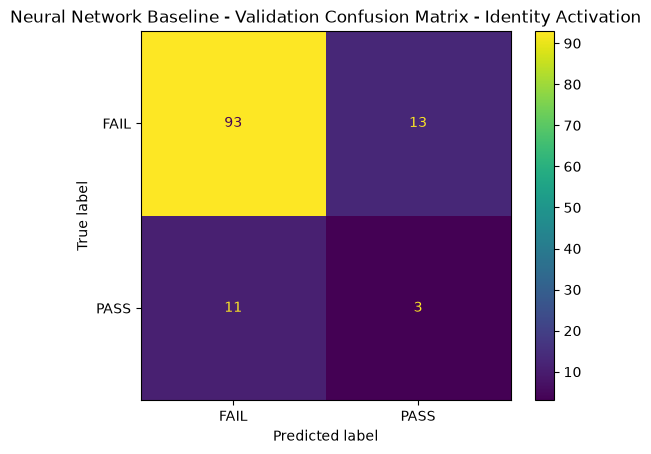

In [74]:
# Organise prediction outcomes by actual and predicted class.
#Generate confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_valid,
    y_pred,
    labels=["FAIL", "PASS"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["FAIL", "PASS"]
)

display.plot()
plt.title("Neural Network Baseline - Validation Confusion Matrix - Identity Activation")
plt.show()

In [73]:
import numpy as np

# Identify the position of the FAIL class.
fail_index = list(model.classes_).index("FAIL")

# Obtain the predicted probability of FAIL for each image.
fail_probabilities = model.predict_proba(X_valid)[:, fail_index]

# Summarise the model's predicted FAIL probabilities.
print("Minimum:", np.min(fail_probabilities))
print("Mean:", np.mean(fail_probabilities))
print("Maximum:", np.max(fail_probabilities))

Minimum: 0.2974635662627011
Mean: 0.6431469935096329
Maximum: 0.8574160726326403
